<a href="https://colab.research.google.com/github/roysam0963/COU07506-labs/blob/main/COU07506_Week01_240242471860.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# COU 07506 – DIGITAL SIGNAL PROCESSING

## WEEK 1 – LAB 0
### Setting Up the DSP Laboratory

**Name:** GAUDENSIA CHARITY MGAYA  
**Registration Number:** 240242471860
**Date:** 23 November 2026  
**Group:**  13


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

print("DSP Laboratory is ready!")


DSP Laboratory is ready!


## Task 1.1 – My First Signals

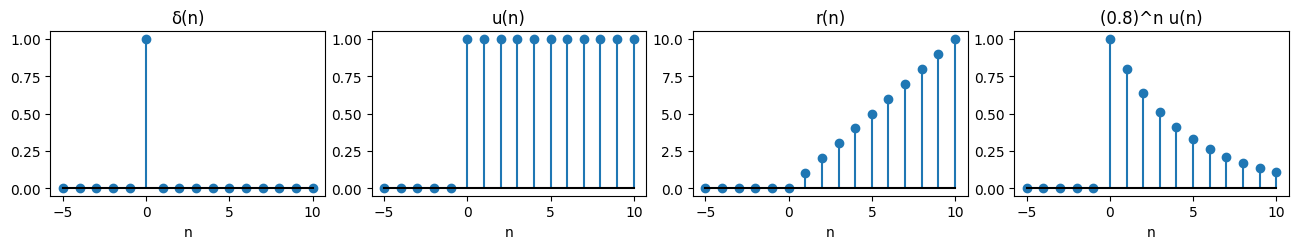

In [2]:
n = np.arange(-5, 11)

delta = (n == 0).astype(float)       # Unit impulse
step = (n >= 0).astype(float)        # Unit step
ramp = n * step                     # Unit ramp
expo = 0.8**n * step                # Real exponential

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))

for ax, x, title in zip(
    axes,
    [delta, step, ramp, expo],
    ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]
):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n")

plt.tight_layout()
plt.show()

## Task 1.2 – Change the Parameters
### (a) Plot exponential signals

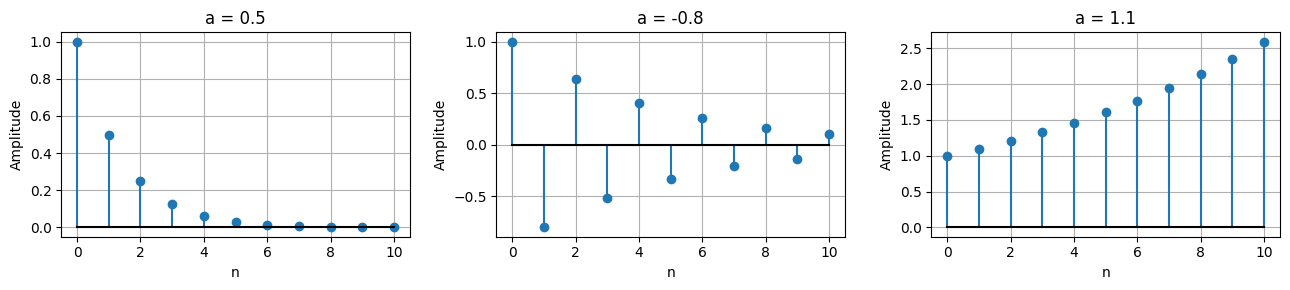

In [3]:
n = np.arange(0, 11)

a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(13, 3))

for ax, a in zip(axes, a_values):
    x = (a**n)
    ax.stem(n, x, basefmt="k-")
    ax.set_title(f"a = {a}")
    ax.set_xlabel("n")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()
plt.show()

### (b)  cosine signals

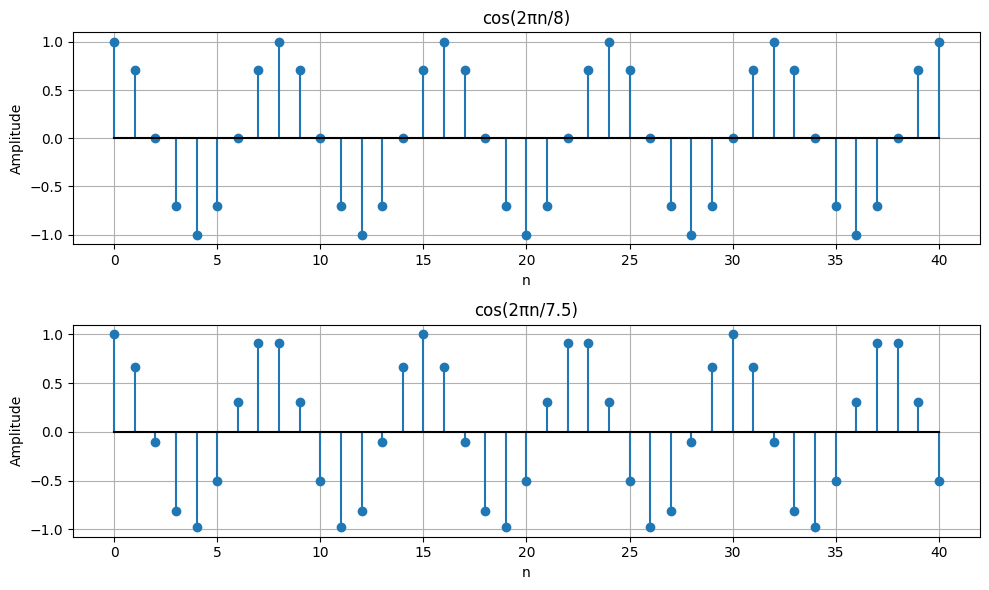

In [4]:
n = np.arange(0, 41)

x1 = np.cos(2 * np.pi * n / 8)
x2 = np.cos(2 * np.pi * n / 7.5)

fig, axes = plt.subplots(2, 1, figsize=(10, 6))

axes[0].stem(n, x1, basefmt="k-")
axes[0].set_title("cos(2πn/8)")
axes[0].set_xlabel("n")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)

axes[1].stem(n, x2, basefmt="k-")
axes[1].set_title("cos(2πn/7.5)")
axes[1].set_xlabel("n")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True)

plt.tight_layout()
plt.show()

**Answer:**

Both signals are periodic.

The first signal has a fundamental period of 8 samples,
while the second signal has a fundamental period of 15 samples.

In [6]:
!ffmpeg -i "/content/my_voice.wav.mp4" -vn -ac 1 -ar 16000 -c:a pcm_s16le "/content/my_voice.wav" -y

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [7]:
import os

print(os.path.exists("/content/my_voice.wav"))

True


Sampling Rate = 16000 Hz
Duration = 5.89 seconds
Number of Samples = 94208


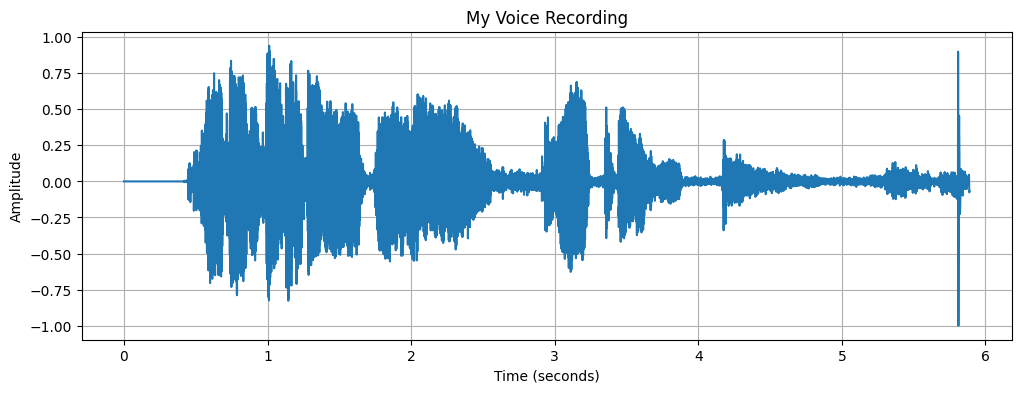

In [8]:
fs, x = wavfile.read("/content/my_voice.wav")

if x.ndim > 1:
    x = x.mean(axis=1)

x = x.astype(float)

peak = np.max(np.abs(x))
if peak > 0:
    x = x / peak

t = np.arange(len(x)) / fs

print(f"Sampling Rate = {fs} Hz")
print(f"Duration = {len(x)/fs:.2f} seconds")
print(f"Number of Samples = {len(x)}")

plt.figure(figsize=(12, 4))
plt.plot(t, x)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("My Voice Recording")
plt.grid(True)
plt.show()

In [9]:
from IPython.display import Audio, display

display(Audio(x, rate=fs))

**Answer:**

The sampling rate of my recording is 16,000 Hz.

This means the audio contains 16,000 samples per second.

For one minute:

Number of samples = Sampling rate × Time

= 16,000 × 60

= 960,000 samples.

Therefore, 960,000 numbers are needed to store one minute of mono audio.

**Answer:**

A stem plot is more appropriate because a discrete-time signal exists only at separate integer values of n.

It shows each individual sample clearly, while a continuous line may suggest that the signal exists between samples.

**Answer:**

It would violate the BIBO stability property.

A stable system must have an absolutely summable impulse response.

Since the exponential signal with a = 1.1 grows continuously, its absolute sum is infinite.

Therefore, the system would be unstable.